In [1]:
import pandas as pd
from datetime import datetime
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./CAE'))
file_path = cPath + '/Y3.labels.csv'
Y3 = pd.read_csv(file_path, parse_dates=['Start'], date_format='%Y-%m-%d %H:%M:%S')
Y3.set_index('Start', drop = False, inplace=True)
file_path = cPath + '/Y4.labels.csv'
Y4 = pd.read_csv(file_path, parse_dates=['Start'], date_format='%Y-%m-%d %H:%M:%S')
Y4.set_index('Start', drop = False, inplace=True)
file_path = cPath + '/Y5.labels.csv'
Y5 = pd.read_csv(file_path, parse_dates=['Start'], date_format='%Y-%m-%d %H:%M:%S')
Y5.set_index('Start', drop = False, inplace=True)

In [3]:
# First, create a new index in each dataframe ignoring the year
def strip_year(df):
    df = df.copy()
    df['datetime_wo_year'] = df.index.to_series().apply(lambda x: x.replace(year=2000))  # 2000 is arbitrary
    return df.set_index('datetime_wo_year')

# Apply to all three dataframes
Y3_new = strip_year(Y3).rename(columns={'USAGE': 'USAGE_Y3'})
Y4_new = strip_year(Y4).rename(columns={'USAGE': 'USAGE_Y4'})
Y5_new = strip_year(Y5).rename(columns={'USAGE': 'USAGE_Y5'})

# Join on the new index (same arbitrary year, matching month/day/hour/minute/second)
merged = Y3_new[['USAGE_Y3']].join(
    Y4_new[['USAGE_Y4']], how='inner'
).join(
    Y5_new[['USAGE_Y5']], how='inner'
)

# Optional: reset index or keep datetime_wo_year
merged.index.name = 'Time'
print(merged)


                     USAGE_Y3  USAGE_Y4  USAGE_Y5
Time                                             
2000-01-01 00:00:00      2256      1737      1216
2000-01-01 00:15:00      2369      1737      1213
2000-01-01 00:30:00      2298      1734      1214
2000-01-01 00:45:00      2252      1740      1329
2000-01-01 01:00:00      2396      1750      1218
...                       ...       ...       ...
2000-04-29 22:45:00      1786      1696      1424
2000-04-29 23:00:00      1790      1692      1425
2000-04-29 23:15:00      1940      1708      1430
2000-04-29 23:30:00      1786      1696      1425
2000-04-29 23:45:00      1793      1696      1427

[11188 rows x 3 columns]


In [4]:
X = merged[['USAGE_Y3', 'USAGE_Y4']].to_numpy()
y = merged['USAGE_Y5'].to_numpy()
print(type(X), X.shape)
print(type(y), y.shape)
model = LinearRegression()
model.fit(X, y)
print(model.intercept_, model.coef_)

<class 'numpy.ndarray'> (11188, 2)
<class 'numpy.ndarray'> (11188,)
41.758097001963165 [0.14795857 0.50641856]


In [5]:
# Step 3: Make predictions using the linear model
y_pred = model.predict(X)  # Predicted values for original X

In [6]:
# Step 4: Fitness evaluation by comparing y (the ideal output) and y_pred (the predicted output)
# Calculate fitness metrics of R², Mean Square Error (MSE), and Root Mean Square Error (rmse) score
r2 = r2_score(y, y_pred)  # Coefficient of determination (R² score)
mse = mean_squared_error(y, y_pred)  # Mean Squared Error
rmse = np.sqrt(mse)  # Root Mean Squared Error

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

R² Score: 0.8456
Mean Squared Error (MSE): 57996.7281
Root Mean Squared Error (RMSE): 240.8251


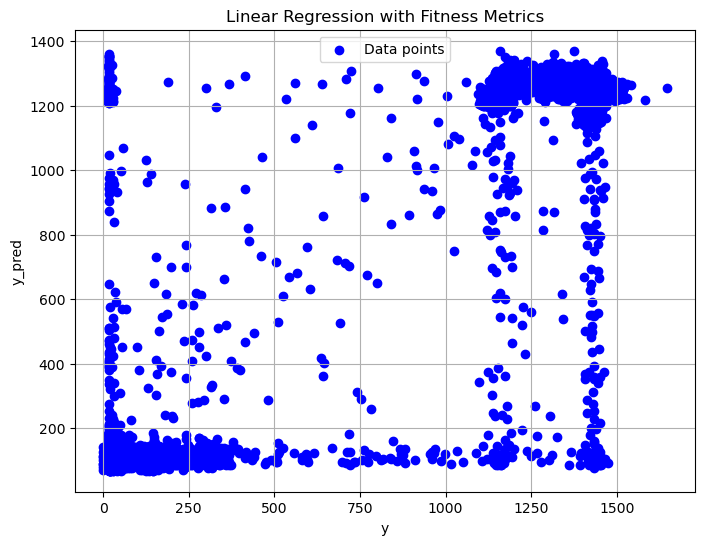

In [7]:
# Step 5: Visualization
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, color="blue", label="Data points")
#plt.plot(X, y_pred, color="red", label="Regression line")
plt.xlabel("y")
plt.ylabel("y_pred")
plt.title("Linear Regression with Fitness Metrics")
plt.legend()
plt.grid(True)
plt.show()

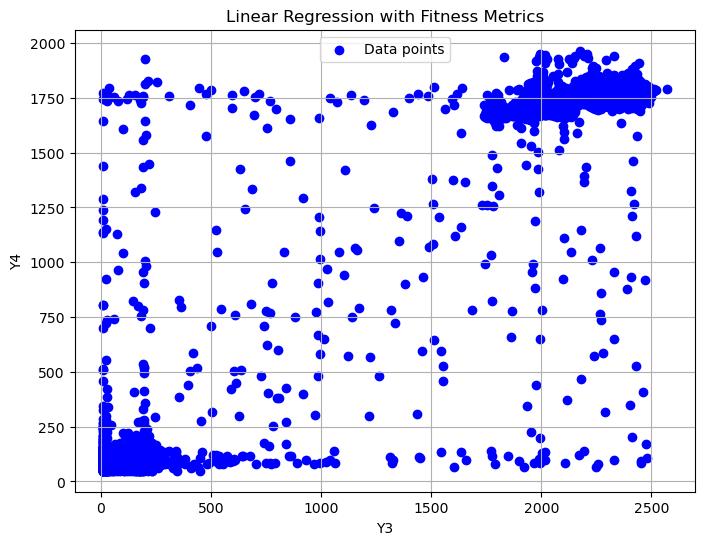

In [8]:
# Step 5: Visualization
plt.figure(figsize=(8, 6))
plt.scatter(merged['USAGE_Y3'], merged['USAGE_Y4'], color="blue", label="Data points")
plt.xlabel("Y3")
plt.ylabel("Y4")
plt.title("Linear Regression with Fitness Metrics")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import plotly.graph_objects as go

# Create the figure
fig = go.Figure()

# Add first usage trace
fig.add_trace(go.Scatter(
    x=merged.index,  # assuming time and date are in the index
    y=merged['USAGE_Y5'],
    mode='lines',
    name='Actual'
))

# Add second usage trace
fig.add_trace(go.Scatter(
    x=merged.index,
    y=y_pred,
    mode='lines',
    name='Predicted'
))

# Customize layout
fig.update_layout(
    title='Actual versus Predicted Usage for Jan-Apr 2025',
    xaxis_title='Time',
    yaxis_title='Usage',
    legend_title='Legend',
    template='plotly_white'
)

# Show the figure
fig.show()


In [13]:
# Join on the new index (same arbitrary year, matching month/day/hour/minute/second)
complete_merged = Y3_new[['USAGE_Y3']].join( Y4_new[['USAGE_Y4']], how='inner')

# Optional: reset index or keep datetime_wo_year
complete_merged.index.name = 'Time'
X = complete_merged[['USAGE_Y3', 'USAGE_Y4']].to_numpy()
y_pred = model.predict(X) 

In [15]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=complete_merged.index,
    y=y_pred,
    mode='lines',
    name='Predicted'
))

fig.update_layout(
    title='Predicted Usage for Jan-Dec 2025',
    xaxis_title='Time',
    yaxis_title='Usage',
    legend_title='Legend',
    template='plotly_white'
)

# Show the figure
fig.show()


In [ ]:
import numpy as np
import pandas as pd

# Assuming your DataFrame is called 'Data' and has a 'USAGE' column
usage_array = Data['USAGE'].values
window_size = 10

# Number of windows with stride 1
num_windows = len(usage_array) - window_size + 1

# Use a list comprehension to generate the sliding windows
usage_vectors = np.array([usage_array[i:i + window_size] for i in range(num_windows)])

# Optional: Convert back to a DataFrame if desired
usage_df = pd.DataFrame(usage_vectors)

# Optionally, assign timestamps (e.g., index of the first point in each window)
usage_df.index = Data.index[:num_windows]

print(usage_df.head())
